**Supplementary analysis: FP32 vs INT8 surgical instrument detection**
This notebook reproduces a supplementary class-, bounding-box-size-, and overlap-stratified error analysis of the FP32 and INT8 TensorFlow Lite exports using the same original held-out test set. 

In [1]:
!pip install -q ultralytics

In [2]:
from pathlib import Path
import os
import shutil
import json
import platform
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display
from ultralytics import YOLO
import ultralytics

FP32_MODEL_PATH = Path("/kaggle/input/models/ainhoa0312/fp32-model/tensorflow2/default/1/YOLOv8n_SurgicalTools_best_fp32 (1).tflite")
INT8_MODEL_PATH = Path("/kaggle/input/models/ainhoa0312/int8-yolo/tensorflow2/default/1/YOLOv8n_SurgicalTools_best_int8 (1).tflite")
TEST_ROOT = Path("/kaggle/working/test_original")

#WARNING: only needed if TEST_ROOT has not been reconstructed yet.
ORIGINAL_TEST_NAMES_TXT =Path("/kaggle/input/datasets/ainhoa0312/test-nombres/test (1).txt")
SOURCE_DATASET_ROOT = Path("/kaggle/input/datasets/ainhoa0312/surgical-data")

OUTPUT_ROOT = Path("/kaggle/working/supplementary_fp32_int8")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
IMAGE_DIR = TEST_ROOT / "images"
LABEL_DIR = TEST_ROOT / "labels"

IMGSZ = 640
BATCH = 1
CONF = 0.25
NMS_IOU = 0.60
CLASSES = {0: "Scalpel", 1: "Forceps", 2: "Straight Scissors", 3: "Curved Scissors"}
print("Output:", OUTPUT_ROOT)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Output: /kaggle/working/supplementary_fp32_int8


Optional: recover the exact original test images (skip if already reconstructed)
This cell matches full Roboflow filenames, including the .rf.<hash> suffix. It prefers the matching label in the corresponding labels/ directory and fails on ambiguity instead of silently selecting an arbitrary duplicated file. It never performs a random split. Reconstructed files are saved to /kaggle/working/test_original/.

In [3]:
#It is an additional step. You don't use it if you already have the dataset split.
def reconstruct_original_test(names_txt, source_root, destination):
    names_txt, source_root, destination = map(Path, (names_txt, source_root, destination))
    if not names_txt.is_file():
        raise FileNotFoundError(names_txt)
    if not source_root.is_dir():
        raise NotADirectoryError(source_root)
    names = [s.strip() for s in names_txt.read_text(encoding="utf-8-sig").splitlines() if s.strip()]
    if len(names) != len(set(names)):
        raise ValueError("Duplicate filenames in original test list")
    if len(names) != 1305:
        raise ValueError(f"Expected 1305 filenames, got {len(names)}")

    lookup = defaultdict(list)
    requested = set(names)
    for p in source_root.rglob("*"):
        if p.is_file() and p.name in requested and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}:
            lookup[p.name].append(p)

    records = []
    problems = []
    for name in names:
        candidates = lookup.get(name, [])
        if not candidates:
            problems.append((name, "image not found"))
            continue
        pairs = []
        for image_path in candidates:
            label_path = image_path.parent.parent / "labels" / (image_path.stem + ".txt")
            if not label_path.is_file():
                problems.append((name, f"label missing next to {image_path}"))
                continue
            pairs.append((image_path, label_path))
        if not pairs:
            continue
        #Detect conflicting duplicates. Use file content, not only filenames.
        import hashlib
        fingerprints = {
            (hashlib.sha256(a.read_bytes()).hexdigest(), hashlib.sha256(b.read_bytes()).hexdigest())
            for a, b in pairs
        }
        if len(fingerprints) > 1:
            problems.append((name, "conflicting image/label copies"))
            continue
        records.append((name, *pairs[0]))

    if problems:
        print("First problems:", problems[:15])
        raise RuntimeError(f"Cannot safely reconstruct test: {len(problems)} issues")
    assert len(records) == 1305
    image_out, label_out = destination / "images", destination / "labels"
    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)
    for name, image_path, label_path in records:
        shutil.copy2(image_path, image_out / name)
        shutil.copy2(label_path, label_out / (Path(name).stem + ".txt"))
    print("Reconstructed", len(records), "original image/label pairs at", destination)

if ORIGINAL_TEST_NAMES_TXT is not None and SOURCE_DATASET_ROOT is not None:
    reconstruct_original_test(ORIGINAL_TEST_NAMES_TXT, SOURCE_DATASET_ROOT, TEST_ROOT)
else:
    print("Reconstruction skipped. Existing TEST_ROOT will be used.")


Reconstructed 1305 original image/label pairs at /kaggle/working/test_original


In [6]:
assert FP32_MODEL_PATH.is_file(), f"FP32 TFLite model missing: {FP32_MODEL_PATH}"
assert INT8_MODEL_PATH.is_file(), f"INT8 TFLite model missing: {INT8_MODEL_PATH}"
assert IMAGE_DIR.is_dir() and LABEL_DIR.is_dir(), "Test images/labels folders do not exist"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
image_paths = sorted(p for p in IMAGE_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
label_paths = sorted(LABEL_DIR.glob("*.txt"))
image_stems = {p.stem for p in image_paths}
label_stems = {p.stem for p in label_paths}
assert len(image_paths) == 1305, f"Expected 1305 images, got {len(image_paths)}"
assert len(label_paths) == 1305, f"Expected 1305 label files, got {len(label_paths)}"
assert image_stems == label_stems, "Image/label stems do not match exactly"

def parse_gt(path):
    items = []
    for line in path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 5:
            raise ValueError(f"Expected 5 YOLO fields in {path}, got: {line}")
        cls = int(float(parts[0]))
        if cls not in CLASSES:
            raise ValueError(f"Unknown class {cls} in {path}")
        x, y, w, h = map(float, parts[1:])
        if not all(np.isfinite([x, y, w, h])) or w <= 0 or h <= 0:
            raise ValueError(f"Invalid GT box in {path}: {line}")
        if min(x-w/2, y-h/2) < -1e-5 or max(x+w/2, y+h/2) > 1+1e-5:
            raise ValueError(f"GT box outside normalized image in {path}: {line}")
        items.append({"class_id": cls, "box": (x-w/2, y-h/2, x+w/2, y+h/2), "area": w*h})
    return items

class_counts = Counter()
for image_path in image_paths:
    for gt in parse_gt(LABEL_DIR / (image_path.stem + ".txt")):
        class_counts[gt["class_id"]] += 1
n_objects = sum(class_counts.values())
assert n_objects == 1874, f"Expected 1874 instances, found {n_objects}"

print("Test images:", len(image_paths))
print("Labeled instances:", n_objects)
print("GT class counts:", {CLASSES[c]: class_counts[c] for c in CLASSES})

config = {
    "path": str(TEST_ROOT.resolve()),
    "train": "images",  # Not used for training in this notebook
    "val": "images",    # Not used for calibration in this notebook
    "test": "images",
    "nc": 4,
    "names": [CLASSES[i] for i in range(4)],
}
YAML_PATH = OUTPUT_ROOT / "test_only.yaml"
YAML_PATH.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
print("Test-only YAML:", YAML_PATH)


Test images: 1305
Labeled instances: 1874
GT class counts: {'Scalpel': 477, 'Forceps': 450, 'Straight Scissors': 458, 'Curved Scissors': 489}
Test-only YAML: /kaggle/working/supplementary_fp32_int8/test_only.yaml


Instance-level matching and error stratification

In [13]:

#STANDARD VALIDATION: FP32 AND INT8
fp32_model = YOLO(str(FP32_MODEL_PATH), task="detect")
int8_model = YOLO(str(INT8_MODEL_PATH), task="detect")

validation_results = {}
per_class_ap = []

for model_name, loaded_model in [
    ("FP32 TFLite", fp32_model),
    ("INT8 TFLite", int8_model)
]:

    metrics = loaded_model.val(
        data=str(YAML_PATH),
        split="test",
        imgsz=IMGSZ,
        batch=BATCH,
        conf=CONF,
        iou=NMS_IOU,
        plots=False,
        project=str(OUTPUT_ROOT),
        name="val_" + model_name.replace(" ", "_").lower(),
        exist_ok=True
    )

    # Overall validation metrics
    validation_results[model_name] = {
        "model": model_name,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map)
    }

    # Per-class validation metrics
    for row_idx, class_id in enumerate(
        metrics.box.ap_class_index
    ):

        p, r, ap50, ap5095 = (
            metrics.box.class_result(row_idx)
        )

        per_class_ap.append({
            "model": model_name,
            "class_id": int(class_id),
            "class_name": CLASSES[int(class_id)],
            "precision": float(p),
            "recall": float(r),
            "AP50": float(ap50),
            "AP50_95": float(ap5095)
        })

df_metrics = pd.DataFrame(
    validation_results.values()
)

df_ap = pd.DataFrame(per_class_ap)

print("Standard Validation")
display(df_metrics.round(4))

print("Per-class Validation")
display(df_ap.round(4))

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

df_metrics.to_csv(
    OUTPUT_ROOT / "standard_validation.csv",
    index=False
)

df_ap.to_csv(
    OUTPUT_ROOT / "standard_ap_by_class.csv",
    index=False
)

print("\nValidation completed successfully.")
print("Results saved to:", OUTPUT_ROOT)


Loading /kaggle/input/models/ainhoa0312/fp32-model/tensorflow2/default/1/YOLOv8n_SurgicalTools_best_fp32 (1).tflite for LiteRT inference...
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1323.0±522.5 MB/s, size: 42.0 KB)
val: Scanning /kaggle/working/test_original/labels.cache... 1305 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1305/1305 391.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1305/1305 14.4it/s 1:300.1ss
                   all       1305       1874      0.946       0.95      0.948       0.82
               Scalpel        477        477      0.955      0.945      0.939      0.757
               Forceps        450        450      0.934      0.918       0.92      0.722
     Straight Scissors        458        458       0.93      0.965       0.96      0.896
       Curved Scissors        489        489      0.965       0.97      0.972      0.903
Spe

,model,precision,recall,mAP50,mAP50_95
0,FP32 TFLite,0.9461,0.9495,0.9478,0.8197
1,INT8 TFLite,0.9215,0.9339,0.9317,0.6857


PER-CLASS STANDARD VALIDATION


,model,class_id,class_name,precision,recall,AP50,AP50_95
0,FP32 TFLite,0,Scalpel,0.9551,0.9455,0.9390,0.7572
1,FP32 TFLite,1,Forceps,0.9336,0.9178,0.9197,0.7224
2,FP32 TFLite,2,Straight Scissors,0.9304,0.9651,0.9602,0.8960
3,FP32 TFLite,3,Curved Scissors,0.9654,0.9698,0.9722,0.9034
4,INT8 TFLite,0,Scalpel,0.9076,0.9268,0.9143,0.6263
5,INT8 TFLite,1,Forceps,0.8839,0.8978,0.8978,0.5951
6,INT8 TFLite,2,Straight Scissors,0.9333,0.9498,0.9436,0.7472
7,INT8 TFLite,3,Curved Scissors,0.9612,0.9613,0.9709,0.7741


Original INT8 score replication (tolerance 0.005): {'precision': True, 'recall': True, 'mAP50': True, 'mAP50_95': True}


In [14]:
def bbox_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, x2-x1) * max(0.0, y2-y1)
    area_a = max(0.0, a[2]-a[0]) * max(0.0, a[3]-a[1])
    area_b = max(0.0, b[2]-b[0]) * max(0.0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter/union if union > 0 else 0.0

def object_size_group(area):
    if area < 0.01:
        return "Small (<1%)"
    if area < 0.05:
        return "Medium (1-5%)"
    return "Large (>=5%)"

def gt_overlap_group(max_iou):
    if max_iou == 0:
        return "None"
    if max_iou < 0.10:
        return "Low"
    if max_iou < 0.30:
        return "Moderate"
    return "High"

def match_predictions(gts, preds, threshold):
    possible = []
    for i, gt in enumerate(gts):
        for j, pred in enumerate(preds):
            if gt["class_id"] == pred["class_id"]:
                v = bbox_iou(gt["box"], pred["box"])
                if v >= threshold:
                    possible.append((v, i, j))
    possible.sort(reverse=True)
    used_gt, used_pred, assigned = set(), set(), {}
    for value, i, j in possible:
        if i not in used_gt and j not in used_pred:
            assigned[i] = value
            used_gt.add(i)
            used_pred.add(j)
    return assigned

def run_matching(loaded_model, model_name):
    rows = []
    processed = set()
    generator = loaded_model.predict(
        source=str(IMAGE_DIR), imgsz=IMGSZ, batch=BATCH,
        conf=CONF, iou=NMS_IOU, stream=True, verbose=False,
    )
    for result in generator:
        filename = Path(result.path).name
        if filename in processed:
            raise RuntimeError(f"Duplicate prediction image {filename}")
        processed.add(filename)
        gts = parse_gt(LABEL_DIR / (Path(filename).stem + ".txt"))
        height, width = result.orig_shape
        preds = []
        if result.boxes is not None:
            for box in result.boxes:
                xyxy = box.xyxy[0].cpu().numpy().astype(float)
                preds.append({
                    "class_id": int(box.cls[0].item()),
                    "confidence": float(box.conf[0].item()),
                    "box": (xyxy[0]/width, xyxy[1]/height, xyxy[2]/width, xyxy[3]/height),
                })
        matches50 = match_predictions(gts, preds, 0.50)
        matches75 = match_predictions(gts, preds, 0.75)
        for i, gt in enumerate(gts):
            max_overlap = max((bbox_iou(gt["box"], other["box"])
                               for j, other in enumerate(gts) if i != j), default=0.0)
            rows.append({
                "model": model_name, "image": filename, "instance_id": i,
                "class_id": gt["class_id"], "class_name": CLASSES[gt["class_id"]],
                "area_fraction": gt["area"],
                "size_group": object_size_group(gt["area"]),
                "max_gt_overlap": max_overlap,
                "overlap_group": gt_overlap_group(max_overlap),
                "detected_iou50": int(i in matches50),
                "detected_iou75": int(i in matches75),
            })
    if len(processed) != 1305 or len(rows) != 1874:
        raise RuntimeError(f"Incorrect test coverage: {len(processed)} images, {len(rows)} GT instances")
    return pd.DataFrame(rows)

fp32_inst = run_matching(fp32_model, "FP32")
int8_inst = run_matching(int8_model, "INT8")

key = ["image", "instance_id"]
fp32_inst = fp32_inst.sort_values(key).reset_index(drop=True)
int8_inst = int8_inst.sort_values(key).reset_index(drop=True)
assert fp32_inst[key].equals(int8_inst[key]), "GT instance identities differ between FP32 and INT8 runs"
assert fp32_inst[["class_id", "size_group", "overlap_group"]].equals(
    int8_inst[["class_id", "size_group", "overlap_group"]]
), "GT metadata differs unexpectedly"

all_instances = pd.concat([fp32_inst, int8_inst], ignore_index=True)
all_instances.to_csv(OUTPUT_ROOT / "instance_level_fp32_int8.csv", index=False)
print("Images:", len({x for x in int8_inst.image}))
print("GT instances per model:", len(int8_inst))
print("Supplementary instance-level matching finished.")


Loading /kaggle/input/models/ainhoa0312/fp32-model/tensorflow2/default/1/YOLOv8n_SurgicalTools_best_fp32 (1).tflite for LiteRT inference...
Loading /kaggle/input/models/ainhoa0312/int8-yolo/tensorflow2/default/1/YOLOv8n_SurgicalTools_best_int8 (1).tflite for LiteRT inference...
Images: 1305
GT instances per model: 1874
Supplementary instance-level matching finished.


In [16]:
def compare_by(group):
    def summarize(df, prefix):
        return df.groupby(group, observed=True).agg(
            n=("detected_iou50", "size"),
            IoU50=("detected_iou50", "mean"),
            IoU75=("detected_iou75", "mean"),
        ).rename(columns={"IoU50": prefix + "_IoU50", "IoU75": prefix + "_IoU75"})

    a = summarize(fp32_inst, "FP32")
    b = summarize(int8_inst, "INT8")
    out = a.join(b, how="outer", lsuffix="_fp32", rsuffix="_int8")
    assert (out["n_fp32"] == out["n_int8"]).all(), "GT counts must match"
    out = out.rename(columns={"n_fp32": "Instances"}).drop(columns="n_int8")
    for col in ["FP32_IoU50", "FP32_IoU75", "INT8_IoU50", "INT8_IoU75"]:
        out[col] *= 100
    out["Delta_IoU50_pp"] = out["INT8_IoU50"] - out["FP32_IoU50"]
    out["Delta_IoU75_pp"] = out["INT8_IoU75"] - out["FP32_IoU75"]
    return out.reset_index()

comparison_class = compare_by("class_name")
comparison_size = compare_by("size_group")
comparison_overlap = compare_by("overlap_group")

for title, table, filename in [
    ("BY CLASS", comparison_class, "comparison_by_class.csv"),
    ("BY OBJECT SIZE", comparison_size, "comparison_by_size.csv"),
    ("BY GT-BOX OVERLAP", comparison_overlap, "comparison_by_overlap.csv"),
]:
    print(title)
    display(table.round(2))
    table.to_csv(OUTPUT_ROOT / filename, index=False)

print("\nOverall instance matching rates (%):")
display(pd.DataFrame({
    "FP32": [100*fp32_inst.detected_iou50.mean(), 100*fp32_inst.detected_iou75.mean()],
    "INT8": [100*int8_inst.detected_iou50.mean(), 100*int8_inst.detected_iou75.mean()],
}, index=["Recall@IoU50", "Recall@IoU75"]).round(2))


BY CLASS


,class_name,Instances,FP32_IoU50,FP32_IoU75,INT8_IoU50,INT8_IoU75,Delta_IoU50_pp,Delta_IoU75_pp
0,Curved Scissors,489,97.34,96.93,96.73,95.71,-0.61,-1.23
1,Forceps,450,93.11,82.44,92.44,75.78,-0.67,-6.67
2,Scalpel,477,94.76,85.12,93.71,78.41,-1.05,-6.71
3,Straight Scissors,458,96.72,95.20,96.51,95.41,-0.22,0.22


BY OBJECT SIZE


,size_group,Instances,FP32_IoU50,FP32_IoU75,INT8_IoU50,INT8_IoU75,Delta_IoU50_pp,Delta_IoU75_pp
0,Large (>=5%),1526,96.46,94.89,95.94,93.91,-0.52,-0.98
1,Medium (1-5%),348,91.38,68.68,90.23,53.74,-1.15,-14.94


BY GT-BOX OVERLAP


,overlap_group,Instances,FP32_IoU50,FP32_IoU75,INT8_IoU50,INT8_IoU75,Delta_IoU50_pp,Delta_IoU75_pp
0,High,447,91.05,84.56,90.60,83.67,-0.45,-0.89
1,Low,116,99.14,88.79,99.14,78.45,0.00,-10.34
2,Moderate,377,92.57,84.62,92.04,81.70,-0.53,-2.92
3,None,934,98.39,94.97,97.54,90.69,-0.86,-4.28



Overall instance matching rates (%):


,FP32,INT8
Recall@IoU50,95.52,94.88
Recall@IoU75,90.02,86.45


**Comparative localization performance of FP32 and INT8 models across instrument classes, object sizes, and bounding-box overlap levels.**

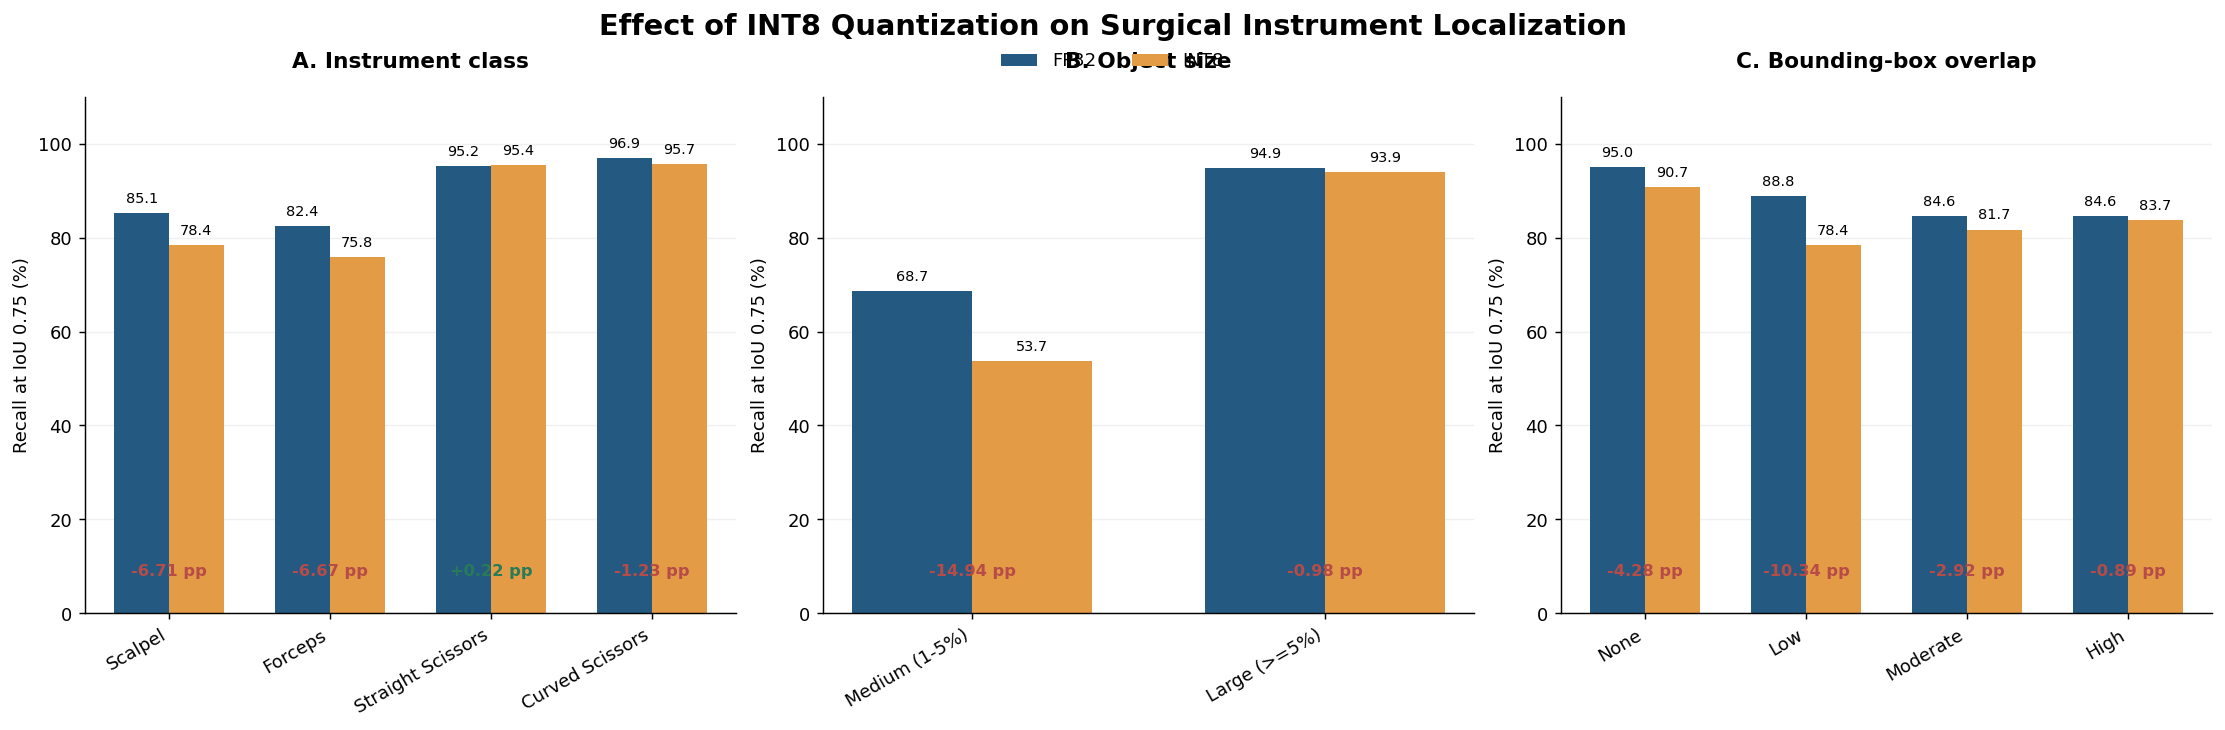

Figure saved successfully.


In [17]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

tables = [
    (
        comparison_class,
        "class_name",
        "A. Instrument class",
        ["Scalpel", "Forceps", "Straight Scissors", "Curved Scissors"]
    ),
    (
        comparison_size,
        "size_group",
        "B. Object size",
        ["Medium (1-5%)", "Large (>=5%)"]
    ),
    (
        comparison_overlap,
        "overlap_group",
        "C. Bounding-box overlap",
        ["None", "Low", "Moderate", "High"]
    )
]

COLOR_FP32 = "#245A81"
COLOR_INT8 = "#E49B45"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5.5),
    constrained_layout=True
)

for ax, (table, group_col, title, order) in zip(axes, tables):

    data = table.set_index(group_col).reindex(order).dropna(
        subset=["FP32_IoU75", "INT8_IoU75"]
    )

    labels = data.index.tolist()
    fp32 = data["FP32_IoU75"].to_numpy()
    int8 = data["INT8_IoU75"].to_numpy()
    delta = int8 - fp32

    x = np.arange(len(labels))
    width = 0.34

    bars1 = ax.bar(
        x - width / 2,
        fp32,
        width,
        color=COLOR_FP32,
        label="FP32"
    )

    bars2 = ax.bar(
        x + width / 2,
        int8,
        width,
        color=COLOR_INT8,
        label="INT8"
    )
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.annotate(
                f"{height:.1f}",
                (
                    bar.get_x() + bar.get_width() / 2,
                    height
                ),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8
            )
            
    for i, difference in enumerate(delta):
        ax.text(
            i,
            8,
            f"{difference:+.2f} pp",
            ha="center",
            fontsize=9,
            fontweight="bold",
            color="#B64B48" if difference < 0 else "#287A58"
        )

    ax.set_title(title, fontweight="bold", pad=16)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")

    ax.set_ylim(0, 110)
    ax.set_ylabel("Recall at IoU 0.75 (%)")
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

fig.suptitle(
    "Effect of INT8 Quantization on Surgical Instrument Localization",
    fontsize=16,
    fontweight="bold"
)

handles, legends = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legends,
    loc="outside upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=2,
    frameon=False
)

SAVE_DIR = Path("/kaggle/working/analisis_int8_original")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    SAVE_DIR / "FP32_vs_INT8_Error_Analysis.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    SAVE_DIR / "FP32_vs_INT8_Error_Analysis.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved successfully.")


**FP32 vs INT8: RECALL BY OBJECT SIZE**

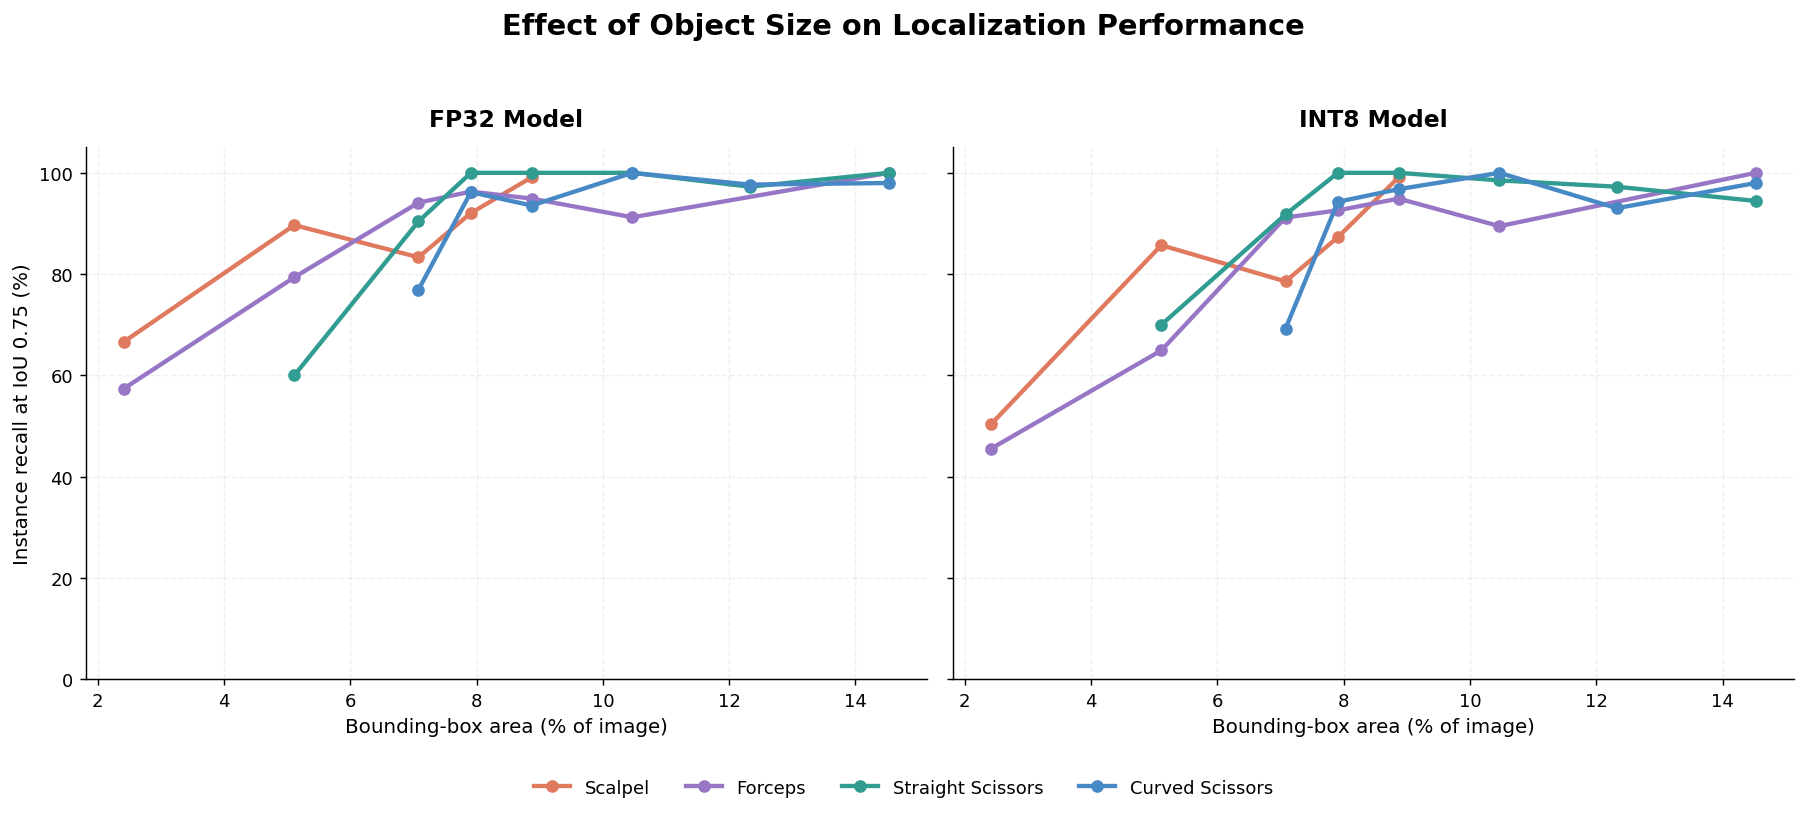

Analysis completed successfully!
FP32 instances: 1874
INT8 instances: 1874
Number of size bins: 8
PNG: /kaggle/working/supplementary_fp32_int8/Recall_vs_Object_Size_FP32_INT8.png
PDF: /kaggle/working/supplementary_fp32_int8/Recall_vs_Object_Size_FP32_INT8.pdf


,class_name,size_bin,Instances,Recall_IoU75,Model,Median_Area_Percent
0,Curved Scissors,2,13,76.92,FP32,7.08
1,Curved Scissors,3,105,96.19,FP32,7.91
2,Curved Scissors,4,31,93.55,FP32,8.87
3,Curved Scissors,5,55,100.00,FP32,10.47
4,Curved Scissors,6,86,97.67,FP32,12.32
5,Curved Scissors,7,199,97.99,FP32,14.53
6,Forceps,0,101,57.43,FP32,2.42
7,Forceps,1,97,79.38,FP32,5.11
8,Forceps,2,34,94.12,FP32,7.08
9,Forceps,3,27,96.30,FP32,7.91


In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

fp32 = fp32_inst.copy()
int8 = int8_inst.copy()

keys = ["image", "instance_id"]

assert len(fp32) == 1874, "Incorrect FP32 instance count"
assert len(int8) == 1874, "Incorrect INT8 instance count"
assert not fp32.duplicated(keys).any()
assert not int8.duplicated(keys).any()

reference = int8[
    keys + ["class_name", "area_fraction"]
].copy()

reference["size_bin"] = pd.qcut(
    reference["area_fraction"],
    q=8,
    labels=False,
    duplicates="drop"
)
bin_info = reference[keys + ["size_bin"]]

fp32 = fp32.merge(
    bin_info,
    on=keys,
    how="left",
    validate="one_to_one"
)

int8 = int8.merge(
    bin_info,
    on=keys,
    how="left",
    validate="one_to_one"
)

assert fp32["size_bin"].notna().all()
assert int8["size_bin"].notna().all()

bin_centers = (
    reference.groupby("size_bin")["area_fraction"]
    .median() * 100
)

classes = [
    "Scalpel",
    "Forceps",
    "Straight Scissors",
    "Curved Scissors"
]

colors = {
    "Scalpel": "#E07A5F",
    "Forceps": "#9876C6",
    "Straight Scissors": "#319C92",
    "Curved Scissors": "#4789C5"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,
    "savefig.dpi": 300
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    sharex=True,
    sharey=True
)

for ax, (model_name, frame) in zip(
    axes,
    [("FP32", fp32), ("INT8", int8)]
):
    for cls in classes:
        subset = frame[
            frame["class_name"] == cls
        ]

        summary = (
            subset.groupby("size_bin")["detected_iou75"]
            .agg(["mean", "size"])
            .reindex(bin_centers.index)
        )

        valid = summary["size"].fillna(0) > 0

        x = bin_centers.loc[valid].to_numpy()
        y = summary.loc[valid, "mean"].to_numpy() * 100

        ax.plot(
            x,
            y,
            marker="o",
            markersize=6,
            linewidth=2.4,
            color=colors[cls],
            label=cls
        )

    ax.set_title(
        f"{model_name} Model",
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Bounding-box area (% of image)"
    )

    ax.set_ylim(0, 105)
    ax.grid(
        axis="both",
        linestyle="--",
        alpha=0.20
    )
    ax.set_axisbelow(True)

axes[0].set_ylabel(
    "Instance recall at IoU 0.75 (%)"
)

fig.suptitle(
    "Effect of Object Size on Localization Performance",
    fontsize=16,
    fontweight="bold",
    y=1.04
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=4,
    frameon=False,
    fontsize=10
)

fig.tight_layout()

SAVE_DIR = Path(
    "/kaggle/working/supplementary_fp32_int8"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

png_path = SAVE_DIR / "Recall_vs_Object_Size_FP32_INT8.png"
pdf_path = SAVE_DIR / "Recall_vs_Object_Size_FP32_INT8.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

curve_data = []

for model_name, frame in [
    ("FP32", fp32),
    ("INT8", int8)
]:
    grouped = (
        frame.groupby(
            ["class_name", "size_bin"],
            observed=True
        )
        .agg(
            Instances=("detected_iou75", "size"),
            Recall_IoU75=("detected_iou75", "mean")
        )
        .reset_index()
    )

    grouped["Model"] = model_name
    grouped["Median_Area_Percent"] = (
        grouped["size_bin"].map(bin_centers)
    )
    grouped["Recall_IoU75"] *= 100

    curve_data.append(grouped)

df_curves = pd.concat(
    curve_data,
    ignore_index=True
)

df_curves.to_csv(
    SAVE_DIR / "Recall_vs_Object_Size_Data.csv",
    index=False
)

print("Analysis completed successfully!")
print("FP32 instances:", len(fp32))
print("INT8 instances:", len(int8))
print("Number of size bins:", len(bin_centers))
print("PNG:", png_path)
print("PDF:", pdf_path)

display(df_curves.round(2))
